# Plan 19: Continual PiCar Learning

Can STM regularization save new experience at matched retention and operational cost? Phase 0 is implementation smoke, not evidence of robot capability or sample savings. [Protocol](plan19.md).

In [ ]:
from pathlib import Path
import os, sys
for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / 'numerical_experiment/picar').is_dir():
        sys.path.insert(0, str(parent))
        break
import pandas as pd
from IPython.display import display
from numerical_experiment.picar import report
ROOT = report.resolve_root('cache/numerical_experiment/picar')  # PICAR_CACHE_ROOT overrides the default
snapshot = report.load_report(ROOT)
print(f'Artifacts: {report.root_label(ROOT)} | {snapshot["status"]}')
print(snapshot['note'])
display(pd.DataFrame(report.progress_rows(snapshot)))
if snapshot['live']:
    display(pd.DataFrame(snapshot['live']))

Artifacts: cache/numerical_experiment/picar | available


Readiness and resource probes describe implementation and operating cost; learning results require fresh paired trajectories.


phase,stage,completed_units,diagnostics,incomplete_units,stopped_units,diagnostic_failures,scientific_units,completed_active_s,status
0,Implementation and acceptance,13,5,0,0,0,0,195.684829,artifacts available
1,Physical/resource readiness,122,0,2,2,0,0,2237.550608,artifacts available; stopped attempts retained
2,Bootstrap and student readiness,0,0,0,0,0,0,NaN,pending
3,Development and retention matching,0,0,0,0,0,0,NaN,pending
4,Fresh paired learning,0,0,0,0,0,0,NaN,pending
5,Efficiency and closeout,0,0,0,0,0,0,NaN,pending


path,phase,status,counts,updated_at,stopped
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase1/fix2-v1/orchestration,1,Fix 2 checkpointed; explicit resume required,{'step': 20},None,True
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase1/fix2-v1/units/pipeline-020281bed68c,1,Fix 2 replay_ewc pipeline starting,{'step': 0},None,True


## Task and Setup

The learner receives RGB, language, executed controls, and elapsed time. Top-down views are for the reader only. Settings and scene media appear only when stored artifacts exist.

In [ ]:
settings = report.settings_rows(snapshot)
display(pd.DataFrame(settings)) if settings else print('Setup artifacts pending.')

mode,version,model,smoke_only,completed_units
smoke,phase0-v1,tiny,True,13
production,phase1-fix1-v1,qwen,True,21
production,phase1-fix1-v2,qwen,True,24
production,phase1-fix2-v1,qwen,True,21
production,phase1-fix2-v2,qwen,True,39
production,phase1-v1,qwen,True,17


## Readiness and Bootstrap

Measured loading, inference, memory, and gradient checks are diagnostics. Language readiness and held-out initial capability remain separate requirements.

Current Qwen probes use one 64x48 image/history step, top-L=1, and 56x56-112x112 processor limits, not the full context-8/batch-4 workload.

In [ ]:
checks = report.readiness_rows(snapshot)
display(pd.DataFrame(checks)) if checks else print('Readiness measurements pending.')
print('Completed diagnostics do not certify all readiness gates. FD convergence requires an explicit recorded pass.')

diagnostic,artifact,load_s,inference_s,peak_reserved_GiB,FD_convergence,error_note
qwen-bc88843d15e3,"completed, smoke only",9.349438,0.599653,6.705078,passed,None
qwen-6c6393a815b0,"completed, smoke only",8.765851,0.548388,6.710938,passed,None
qwen-87cc7cfc1f74,"completed, smoke only",8.744256,0.556171,6.716797,passed,None
qwen-acceptance-v1,"completed, smoke only",19.523148,0.968665,6.820312,not certified,None
qwen-acceptance-v2,"completed, smoke only",9.881817,0.618010,6.714844,passed,None


Completed diagnostics do not certify all readiness gates. FD convergence requires an explicit recorded pass.


CPU acceptance: 280 tests; 0 failures, 0 errors, 0 skipped. Paired smoke completed.


## Phase 1: Feasibility and Forecast

Can a controllable, language-conditioned task fit the online resource budget? Phase 1 measures this before learning curves. Resource probes, scene/role audits, and qualified forecasts are smoke-only diagnostics, not scientific learning results. Only completed scalar artifacts are used; missing measurements remain unavailable.

Selected recipe,Settings
Model,top layers=1; hidden size=64; ltm rank=4; stm rank=1
Online batch,context length=8; batch=1; fd probes=1; fisher draws=1
Sensor / tokens,image width=160; image height=120; max pixels=19200; max tokens=2048


Probe (* selected),Recipe,Status,Infer s,Control fit s,FD fit s,Fisher s
1 *,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/1,passed; resource only,0.79,1.71,1.98,0.866
2,L=1 H=64 C=16 B=1; ranks=4/1; FD/F=1/1,oom,2.69,unavailable,unavailable,unavailable
3,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/1,inadmissible,0.982,2.12,4.21,1.06
4,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/4,passed; resource only,0.782,1.75,2,1.07
5,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/2,passed; resource only,0.804,1.73,2,0.932
6,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=2/1,passed; resource only,0.789,1.72,2.26,0.872


Additional timings (probe),Load s,NLL backward s,FD backward s,Teacher s,Evaluator s
1,9.24,0.839,0.963,0.172,0.169


Showing 6 of 10 completed probes; all trials and exact recipes remain in archived units. Timings are individual operations, not a summed update cost; unavailable is not zero. A recorded selection (*) is not competence or admission certification.


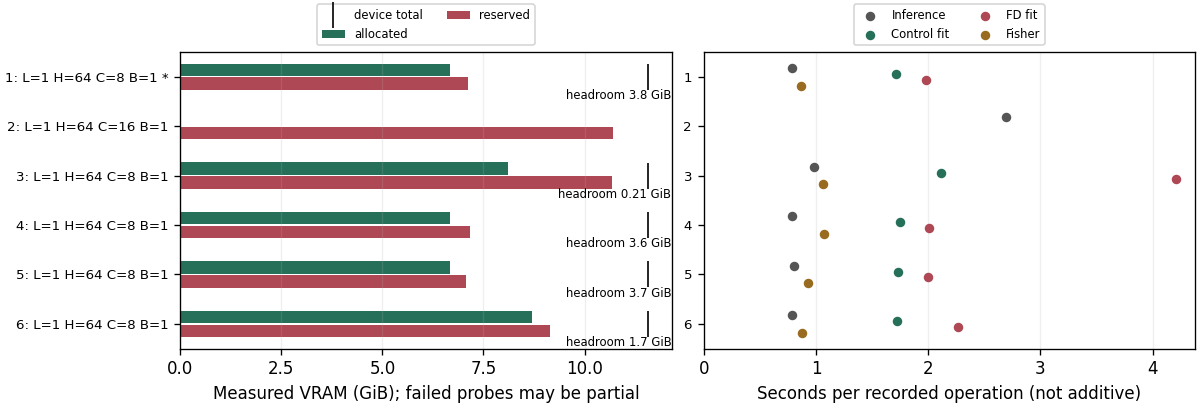

Forecast source (latest completed): forecast-4pairs-1200.


Paired replicas,New transitions / arm,Total active hours,Within 20 h
6,2400,38.9--55.7,false
4,1200,19.0--28.0,false


Stage,Low h,High h
2: Bootstrap,0.577,0.917
3: Development,5.85,9.3
4: Fresh pairs,12.1,16.8
5: Closeout,0.25,0.75
Reported total,19,28


Recorded budget fit: false. Total scope is as recorded, not inferred by adding phase estimates or concurrent probe charges.


Forecast includes shared bootstrap, development, 72 evaluation episodes per arm, sleep, and checkpoint I/O. One optimizer event and one eviction Fisher per new transition are assumed; larger sleep batches and skill rescue work need remeasurement. Ranges are engineering allowances, not confidence intervals.


Blockers: ["Frozen Qwen teacher did not demonstrate useful A skill in this small readiness pilot.", "Frozen RGB potential did not consistently rank success above far failure.", "Real-time inference/update pilot missed more than 10% of non-startup ...


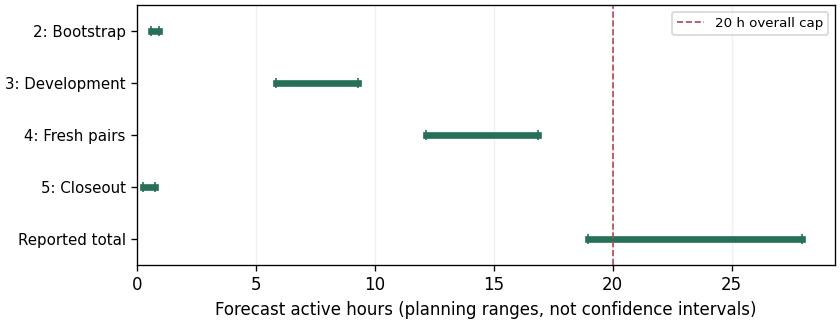

Fresh scope,Raw training frames / records (GB),Retain every full checkpoint (GB)
6 pairs x 2400,13.5,1.55e+03
4 pairs x 1200,4.67,393


Storage is a fresh-training projection, not a total allocation: development, evaluation video, and failed attempts add bytes. Keeping every transaction snapshot is not an admitted policy; bounded recovery checkpoints plus an append-only event journal/archive are needed before learning.


Audit,Check / metric,Value
Scene,source (latest completed),scene-ec88e89988aa; 3 archived unit(s)
Scene,limitations,"[""Privileged controller is not a teacher or student performance estimate."", ""Accelerated CPU feedback does not test wall-clock inference deadlines."", ""No physical calibration or hardware validation."", ""Frozen Qwen panel scoring belongs t..."
Scene,scene count,4
Scene,successes,1
Scene,accelerated,true
Scene,all feasible,false
Scene,diagnostic,PRIVILEGED scripted feasibility diagnostic; not teacher/student demonstrations
Scene,frozen evaluator status,pending_parent_RGB_only_scoring
Scene,hardware connected,false
Scene,reward panel truth verified,true


Probe,Recorded numerical checks
1,control_last_losses.data=8.15; control_last_losses.ewc=0.00561; control_last_losses.fd=0; control_last_losses.fisher_scale=0.000307; control_last_losses.kappa=3.07e-05; control_last_losses.ridge=0.00042; control_last_losses.total=8.16; c...
2,finite_action=true
3,control_last_losses.data=8.16; control_last_losses.ewc=0.00526; control_last_losses.fd=0; control_last_losses.fisher_scale=0.00028; control_last_losses.kappa=2.8e-05; control_last_losses.ridge=0.000381; control_last_losses.total=8.16; co...
4,control_last_losses.data=8.15; control_last_losses.ewc=0.0121; control_last_losses.fd=0; control_last_losses.fisher_scale=0.000632; control_last_losses.kappa=6.32e-05; control_last_losses.ridge=0.000833; control_last_losses.total=8.16; c...
5,control_last_losses.data=8.15; control_last_losses.ewc=0.0207; control_last_losses.fd=0; control_last_losses.fisher_scale=0.00114; control_last_losses.kappa=0.000114; control_last_losses.ridge=0.00144; control_last_losses.total=8.17; con...
6,control_last_losses.data=8.15; control_last_losses.ewc=0.00561; control_last_losses.fd=0; control_last_losses.fisher_scale=0.000307; control_last_losses.kappa=3.07e-05; control_last_losses.ridge=0.00042; control_last_losses.total=8.16; c...


Probe,Blocker / limitation,Recorded reason
2,oom,"CUDA out of memory. Tried to allocate 570.00 MiB. GPU 0 has a total capacity of 11.57 GiB of which 574.19 MiB is free. Including non-PyTorch memory, this process has 10.40 GiB memory in use. Of the allocated memory 9.76 GiB is allocated ..."
3,inadmissible,insufficient reserved GPU headroom


Archived artifacts: /home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar

Readiness numbers are recorded diagnostics, not held-out student competence or sample savings. Missing role, language, fallback, or physical checks remain unverified. Top-0 is diagnostic-only. Strong sim-to-real claims require physical calibration. Forecast accounting must include evaluation, sleep, failed attempts, reporting and I/O, charged once; a budget extension requires approval.


In [ ]:
from numerical_experiment.picar.phase1_report import display_phase1
display_phase1(snapshot)

### Phase 1 Fix 1: Grounding and Online Readiness

The original run found an unvalidated action/reward interface and updates that blocked control. This repair checks native-model parity, clearer motor semantics and visual history, then cooperative scheduling. Original results remain above. These are engineering diagnostics, not STM learning results; the newest repair revision is shown without pooling attempts.

Scene,Native/split relative error,Parity,Mass on action digits,Native description
far_deadline_failure,0,True,1,"The red ball is located at the top center of the image, while the blue block is positioned at the bottom center. The path appears to be clear, as there are no obstacles directly in"
near_goal_not_success,0,True,1,"The red ball is located on the ground in front of the blue block. The path appears to be clear, as there are no obstacles directly in the way."
stopped_success,0,True,1,"The red ball is located on the ground in the center of the image, slightly to the right. The blue block is positioned behind the red ball, closer to the top edge of the image. The"
obstacle_collision,0,True,1,"The red ball is located at the top center of the image, approximately 0.5 units above the ground plane. The blue block is positioned on the ground plane, covering the bottom half o"


Role interface,Valid teacher outputs,Instruction contrasts,Visual reward ordering
legacy,True,False,False
grounded-low,True,False,False
grounded-visual-v2,True,True,False
generated-visual-v2,True,True,False


Teacher,Panel,Domain,Successes / episodes
grounded-visual-v2,development,A,0/2
grounded-visual-v2,development,B,0/2
generated-visual-v2,development,A,0/2
generated-visual-v2,development,B,0/2


History,Period (s),Cooperative,Fallbacks / non-startup,Fallback (%),Update handoffs,Deadline guide
4,0.75,False,4/24,16.7,0,False
4,0.75,True,0/20,0.0,6,True
4,1.00,False,2/17,11.8,0,False
4,1.00,True,0/15,0.0,4,True
4,1.25,False,0/12,0.0,0,True
4,1.25,True,0/13,0.0,2,True


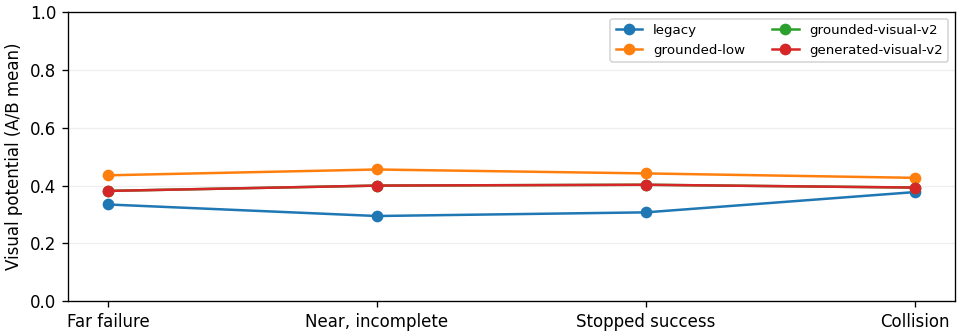

Repair compute: 5.5 active minutes. Later learning phases remain unstarted.
A competent language-responsive Qwen teacher is not validated on 20 fresh layouts.
Visual shaping potential is not validated; no-shaping remains an unselected versioned fallback.


Execution notes: Revision 2 corrected conflicting default-mission prompting; version 1 prompt remains available. A Tk rendering backend abort interrupted revision 2; completed units were preserved. Headless Agg rendering was enabled, then --resume verified/skipped completed diagnostics and retried the incomplete short control pilot.


In [ ]:
from numerical_experiment.picar.phase1_fix_report import display_repair
display_repair(snapshot)

### Phase 1 Fix 2: Dense Visual Rewards and Robot Workflow

The prior readiness checks used a completion probability and a potential difference, which did not reproduce the earlier robot's graded visual rewards. This repair generates explicit 0–10 scores, checks unobstructed approach before obstacle navigation, and audits the complete reward-to-return pipeline. Target contact is success; obstacle/wall contact is failure. Historical Fix 1 results remain above. These are readiness diagnostics, with no STM efficacy claim.

The initial Fix 2 attempt (`fix2-v1`) rejected valid JSON inside Markdown fences. Its raw responses and artifacts remain available; those rejected responses are not a navigation-performance estimate. The revised parser accepts one exact JSON fence while retaining strict values/keys. The revised timing pilot also masks retired recurrent predecessors.

Software acceptance,Result
passed,637 passed in 42.56s


Rubric,Panel,Valid scores,Absent/present,Correct approach pairs,Readiness guide
legacy,development,True,True,1/12,False
contact,development,True,True,5/12,False
contact,validation,True,True,8/12,False


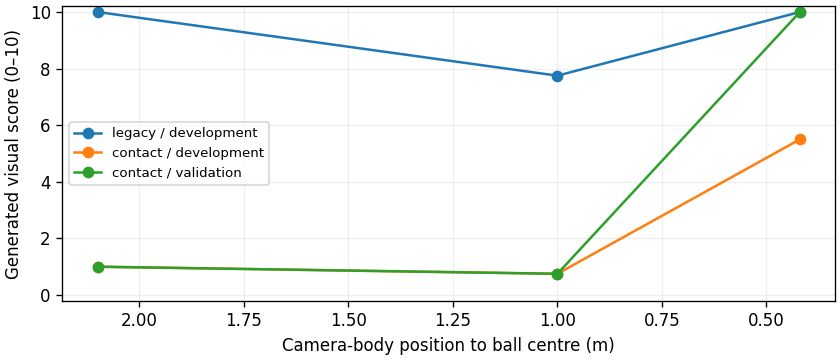

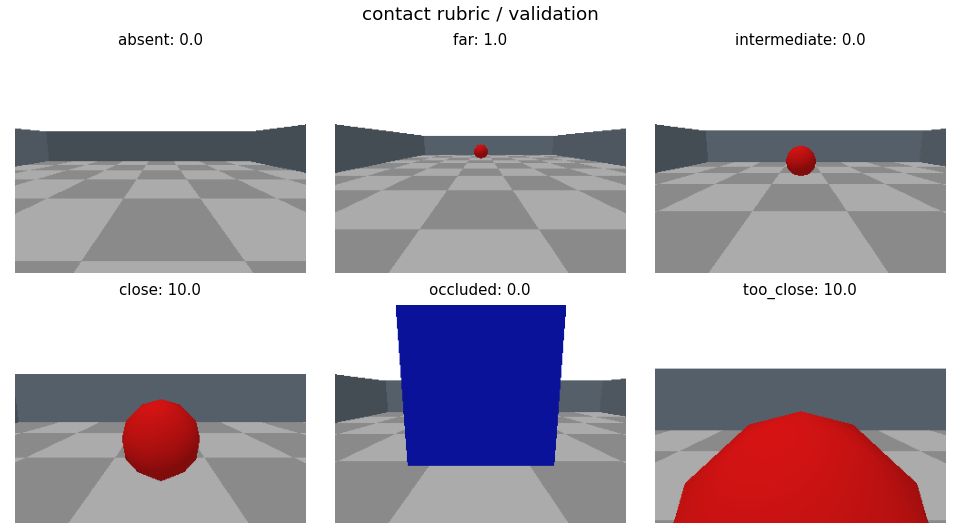

Teacher,Panel,Task,Domain,Successes / episodes
ported,development,Unobstructed ball,A,2/3
ported,development,Unobstructed ball,B,1/3
grounded,development,Unobstructed ball,A,0/3
grounded,development,Unobstructed ball,B,0/3
ported,development,Obstacle + ball,A,0/3
ported,development,Obstacle + ball,B,0/3
grounded,development,Obstacle + ball,A,0/3
grounded,development,Obstacle + ball,B,0/3


Teacher rollouts use accelerated physics for task diagnosis. Their success rates do not establish real-time Qwen control. Full real-time pipeline timing below uses the student.


Return bins,Tied progress pairs,Gradient ordering,Max log-weight rounding error,Selected
41,0,True,0.0439,True
81,0,True,0.0222,False
161,0,True,0.0112,False


Timing model context,Timing replay capacity,New/replay batch,Return bins,Physical control period (s)
4,8,1 / 1,41,1.0


Loss,Non-startup fallbacks,Updates,Retired records,Peak label backlog,Pending after drain,Total active seconds
replay_ewc,0/44,44,36,17,0,84.5
stm_fd,0/44,44,36,17,0,84.2


Conditional study,Total forecast (h),Fits 20-hour cap
6 pairs x 2400 observations/arm,21.4 to 30.8,False
4 pairs x 1200 observations/arm,11.6 to 17.2,True


Displayed totals add 10.6 minutes of earlier acceptance/profiling to the sealed forecast's repair ledger. Forecasts assume an optimizer event and eventual Fisher admission per new observation; fit wall times include cooperative waits, so the serial sum is conservative. They do not establish teacher/student competence or budget approval.


Requirement,Status
Causal instructions/countdown,implemented and tested
Contact semantics,CPU Bullet tests passed
Numeric rewards and return pipeline,implemented and audited
Pi and speech interfaces,injected/recorded-input acceptance passed; physical validation pending
Real-time service,"measured, including stopped labeling/drain; see limitations"
Retired sleep option,default-off; CPU acceptance passed


Fix 2 active compute: 17.9 min; all repair work: 31.1 min.
Generated visual scores or return resolution remain below the readiness guide.
Full obstacle-task Qwen competence is not validated on 20 fresh layouts.
The full study remains subject to resource review and Phase 2 student readiness.


In [ ]:
from numerical_experiment.picar.phase1_fix2_report import display_fix2
display_fix2(snapshot)

## Development

Retention matching and recipe selection use development artifacts only. A selected recipe and fresh-run authorization are unavailable until explicitly recorded.

## Fresh Learning

Held-out B success measures acquisition. A failure increase measures loss of initial capability. Curves use unique new transitions, not replay exposures; smoke units are excluded.

In [ ]:
figure = report.plot_learning(snapshot)
display(figure) if figure is not None else print('Fresh held-out paired trajectories pending.')
effect = report.paired_failure_summary(snapshot)
display(pd.DataFrame([effect])) if effect['n_pairs'] else print('Paired failure effect unavailable: no complete scientific pairs.')

Fresh held-out paired trajectories pending.


Paired failure effect unavailable: no complete scientific pairs.


## Efficiency

A target needs two consecutive measured checkpoints meeting capability and retention gates. Interpolate only in observed brackets on the outward ramp/B hold. f is the fraction of new samples saved; c is the operational compute ratio; S=f/c. Half the experience at twice the compute gives S=0.25. Censored draws stay visible. No efficiency estimate is produced without supported crossings and recorded operational costs.

## Behavior and Mechanisms

Common preselected-seed clips show synchronized ego/top-down views with actual timestamps and controls. A separately selected failure gallery must be labeled. Missing media does not block scalar analysis.

In [ ]:
from IPython.display import HTML
display(HTML(report.media_links(snapshot)))

Stored behavior media links; missing clips remain explicitly labeled.

## Conclusion

**Fix 2 is implemented and its diagnostics are complete.** The ported Qwen interface reached the ball in 3/6 unobstructed trials. The full obstacle task achieved 0/12; fresh 20-layout validation was not admitted.

Numeric visual scores now work and separate absence from close approach, but remain coarse and miss the strict far-to-near ordering guide. Return-bin/actor-weight resolution passes with 41 bins. Both finite multi-episode student pilots completed with zero non-startup fallbacks, including online updates and charged stopped labeling/sleep. This does not prove uninterrupted one-update-per-observation service.

The primary study remains at the resource/task check-in. Default-off retired sleep and the Pi/speech interfaces have software acceptance; physical calibration and real speech inference remain unvalidated. No physical robot was operated and no STM sample-efficiency result is claimed. Earlier attempts and their source snapshots remain available.